# Assignment 2: Self-Supervised Visual Representation Learning
**ITCS 6169/8169 Computer Vision** · 16-class scene/flower classification from 2,400 training images

**Question:** can we learn better representations from the same 2,400 images without relying only on labels?

**No external pretraining.** Every network here is randomly initialised and trained only on `data/train`.
`data/test` is used once, at the end, to report accuracy. `data/test2` (unlabelled) only receives predictions.

| ID | Experiment | Question it answers |
|---|---|---|
| E0 | Random-init backbone, frozen features | Floor: how much does a random CNN already give a linear probe? |
| E1 | Supervised baseline (CE only) | Reference accuracy |
| E2 | SimCLR pretraining → linear probe / kNN / full fine-tune | Does contrastive SSL learn useful features from 1,920 images? |
| E3 | Rotation-prediction pretraining → fine-tune | Is a simpler pretext task as good as contrastive learning? |
| E4 | Joint CE + SimCLR from scratch, and a λ=0 control | Does adding the SSL loss help, beyond the two-view strong augmentation? |
| E5 | SimCLR augmentation ablation (short schedule) | Which augmentations matter on this grayscale dataset? |
| E6 | Label-efficiency: 10/25/50/100 % labels | Does SSL help more when labels are scarce? |
| E7 | Best recipe | Strongest model built from the findings above |

Every experiment caches its result in `runs/`, so re-running the notebook skips finished work.
Set `FORCE_RERUN = True` to retrain from scratch.

**Running on Google Colab:** choose *Runtime → Change runtime type → T4 GPU*. Upload the folder
`CVAssignment2` (with `data/train`, `data/test` and `data/test2` inside) to the top level of *My Drive*, then
*Run all*. The next cell mounts Drive, and all checkpoints and results are written to
`My Drive/CVAssignment2/runs`, so they survive a disconnect. If the session drops, run all again and finished
experiments are loaded from the cache.

In [1]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/CVAssignment2")   # change if you put the folder elsewhere
print("working dir:", os.getcwd(), "| data found:", os.path.isdir("data/train"))

working dir: /Users/anushareddy/Desktop/CVAssignment2 | data found: True


In [2]:
import json, time, math, random
from IPython.display import display
from pathlib import Path
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

DATA_ROOT = Path(os.environ.get("DATA_ROOT", "data"))
RUN_DIR = Path(os.environ.get("RUN_DIR", "runs")); RUN_DIR.mkdir(exist_ok=True)
FORCE_RERUN = False
SEED = 0
STORE = 72   # images are cached at 72x72 grayscale
IMG = 64     # network input after (random-resized) cropping
EPOCH_SCALE = float(os.environ.get("EPOCH_SCALE", 1.0))  # e.g. 0.02 for a smoke test

if torch.cuda.is_available(): DEVICE = "cuda"
elif torch.backends.mps.is_available(): DEVICE = "mps"
else: DEVICE = "cpu"
torch.set_num_threads(os.cpu_count())
torch.backends.cudnn.benchmark = True
print("device:", DEVICE, "| torch", torch.__version__, "| epoch scale", EPOCH_SCALE)

def E(n):  # scaled epoch count
    return max(1, int(round(n * EPOCH_SCALE)))

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

device: mps | torch 2.15.0 | epoch scale 1.0


## 1. Data
Assignment 1 found that all 15 scene classes are grayscale while every *Flower* image is RGB, so a model can
recognise flowers from colour alone. We convert everything to grayscale (1 channel) to remove that shortcut.
Images are resized (short side) and centre-cropped to 72×72 and held in memory as a uint8 tensor;
all augmentation then runs batched on the training device.

train (2400, 1, 72, 72), test (400, 1, 72, 72), test2 400, classes 16
per-class train counts: [150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150]
train split 1920, val split 480, mean 0.457, std 0.241


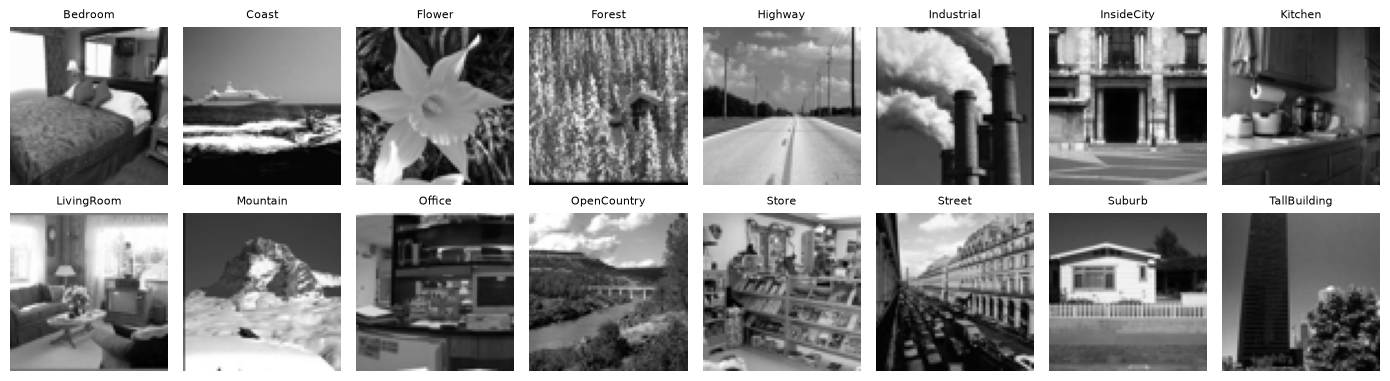

In [3]:
def load_folder(root):
    classes = sorted(d.name for d in root.iterdir() if d.is_dir())
    X, y = [], []
    for ci, c in enumerate(classes):
        for f in sorted((root / c).glob("*.jpg")):
            X.append(load_img(f)); y.append(ci)
    return torch.stack(X), torch.tensor(y), classes

def load_img(f):
    im = Image.open(f).convert("L")
    w, h = im.size; s = STORE / min(w, h)
    im = im.resize((max(STORE, round(w * s)), max(STORE, round(h * s))), Image.BICUBIC)
    w, h = im.size; l, t = (w - STORE) // 2, (h - STORE) // 2
    im = im.crop((l, t, l + STORE, t + STORE))
    return torch.from_numpy(np.asarray(im, dtype=np.uint8).copy())[None]

X_all, y_all, CLASSES = load_folder(DATA_ROOT / "train")
X_test, y_test, test_classes = load_folder(DATA_ROOT / "test")
assert test_classes == CLASSES
test2_files = sorted((DATA_ROOT / "test2").glob("*.jpg"), key=lambda p: int(p.stem.split("_")[-1]) if p.stem.split("_")[-1].isdigit() else p.stem)
X_test2 = torch.stack([load_img(f) for f in test2_files]) if test2_files else None
K = len(CLASSES)
print(f"train {tuple(X_all.shape)}, test {tuple(X_test.shape)}, test2 {len(test2_files)}, classes {K}")
print("per-class train counts:", torch.bincount(y_all).tolist())

# stratified 80/20 split (same protocol as Assignment 1, seed 0)
g = torch.Generator().manual_seed(SEED)
tr_idx, va_idx = [], []
for c in range(K):
    idx = torch.nonzero(y_all == c).flatten()
    idx = idx[torch.randperm(len(idx), generator=g)]
    n_va = round(0.2 * len(idx))
    va_idx += idx[:n_va].tolist(); tr_idx += idx[n_va:].tolist()
tr_idx, va_idx = torch.tensor(sorted(tr_idx)), torch.tensor(sorted(va_idx))
X_tr, y_tr, X_va, y_va = X_all[tr_idx], y_all[tr_idx], X_all[va_idx], y_all[va_idx]
MEAN = (X_tr.float() / 255).mean().item(); STD = (X_tr.float() / 255).std().item()
print(f"train split {len(tr_idx)}, val split {len(va_idx)}, mean {MEAN:.3f}, std {STD:.3f}")

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for c, ax in enumerate(axes.flat):
    ax.imshow(X_tr[y_tr == c][0, 0], cmap="gray"); ax.set_title(CLASSES[c], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Batched augmentations (grayscale)
Each image in a batch gets its own random crop/flip/photometric parameters. Crops are done with an affine
sampling grid, so a whole batch is augmented in one call on CPU, CUDA or MPS.

* **crop**: random-resized crop, area fraction `scale`, aspect ratio 3/4 to 4/3, output 64×64
* **flip**: horizontal, p = 0.5
* **jitter**: brightness and contrast (no hue/saturation since images are grayscale), probability `p_jitter`
* **blur**: Gaussian blur σ ∈ [0.1, 1.2], probability `p_blur`
* **solarize**: invert pixels above 0.5, probability `p_solar`

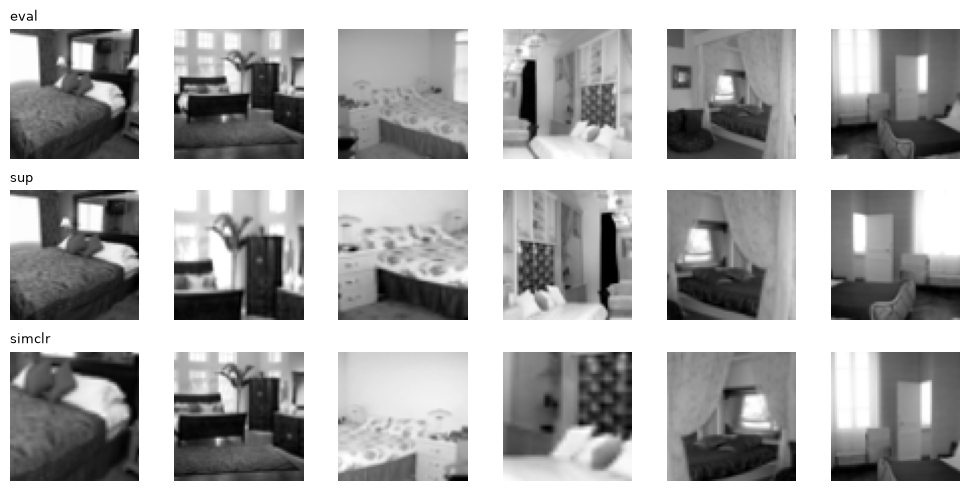

In [4]:
AUG = {
    "eval":     dict(scale=None),
    "sup":      dict(scale=(0.35, 1.0), jitter=0.3, p_jitter=0.8, p_blur=0.0, p_solar=0.0),
    "simclr":   dict(scale=(0.2, 1.0),  jitter=0.5, p_jitter=0.8, p_blur=0.5, p_solar=0.1),
    # ablations (E5): remove one family at a time
    "no_crop":  dict(scale=(0.9, 1.0),  jitter=0.5, p_jitter=0.8, p_blur=0.5, p_solar=0.1),
    "no_photo": dict(scale=(0.2, 1.0),  jitter=0.0, p_jitter=0.0, p_blur=0.0, p_solar=0.0),
    "no_blur":  dict(scale=(0.2, 1.0),  jitter=0.5, p_jitter=0.8, p_blur=0.0, p_solar=0.0),
}

def _blur(x, sigma):
    n, k = x.shape[0], 7
    r = torch.arange(k, device=x.device, dtype=x.dtype) - k // 2
    w = torch.exp(-(r[None] ** 2) / (2 * sigma[:, None] ** 2)); w = w / w.sum(1, keepdim=True)
    xp = F.pad(x.transpose(0, 1), (k // 2,) * 4, mode="reflect")      # (1, n, H, W)
    xp = F.conv2d(xp, w[:, None, None, :], groups=n)
    xp = F.conv2d(xp, w[:, None, :, None], groups=n)
    return xp.transpose(0, 1)

def augment(xb, name):
    """xb: uint8 (n,1,72,72) on any device -> normalised float (n,1,64,64)."""
    a = AUG[name]; x = xb.float() / 255; n, dev = x.shape[0], x.device
    if a["scale"] is None:
        x = F.interpolate(x, size=(IMG, IMG), mode="bilinear", antialias=True, align_corners=False)
        return (x - MEAN) / STD
    area = torch.empty(n, device=dev).uniform_(*a["scale"])
    logr = torch.empty(n, device=dev).uniform_(math.log(3 / 4), math.log(4 / 3)); r = logr.exp()
    w = (area * r).sqrt().clamp(max=1); h = (area / r).sqrt().clamp(max=1)
    cx = (torch.rand(n, device=dev) * 2 - 1) * (1 - w); cy = (torch.rand(n, device=dev) * 2 - 1) * (1 - h)
    flip = torch.where(torch.rand(n, device=dev) < 0.5, -1.0, 1.0)
    theta = torch.zeros(n, 2, 3, device=dev)
    theta[:, 0, 0] = w * flip; theta[:, 0, 2] = cx; theta[:, 1, 1] = h; theta[:, 1, 2] = cy
    grid = F.affine_grid(theta, (n, 1, IMG, IMG), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)
    if a["p_jitter"] > 0:
        on = (torch.rand(n, 1, 1, 1, device=dev) < a["p_jitter"]).float()
        b = 1 + (torch.rand(n, 1, 1, 1, device=dev) * 2 - 1) * a["jitter"]
        c = 1 + (torch.rand(n, 1, 1, 1, device=dev) * 2 - 1) * a["jitter"]
        m = x.mean((2, 3), keepdim=True)
        xj = ((x - m) * c + m) * b
        x = (on * xj + (1 - on) * x).clamp(0, 1)
    if a["p_blur"] > 0:
        on = (torch.rand(n, 1, 1, 1, device=dev) < a["p_blur"]).float()
        sigma = torch.empty(n, device=dev).uniform_(0.1, 1.2)
        x = on * _blur(x, sigma) + (1 - on) * x
    if a["p_solar"] > 0:
        on = (torch.rand(n, 1, 1, 1, device=dev) < a["p_solar"]) & (x > 0.5)
        x = torch.where(on, 1 - x, x)
    return (x - MEAN) / STD

xb = X_tr[:6].to(DEVICE)
fig, axes = plt.subplots(3, 6, figsize=(10, 5))
for row, name in enumerate(["eval", "sup", "simclr"]):
    out = augment(xb, name).cpu()
    for j in range(6):
        axes[row, j].imshow(out[j, 0], cmap="gray"); axes[row, j].axis("off")
    axes[row, 0].set_title(name, loc="left", fontsize=9)
plt.tight_layout(); plt.show()

## 3. Model
A small ResNet (4 stages, 2 convs per residual block, widths 32/64/128/256, ~1.2 M parameters) with a
stride-2 3×3 stem for 64×64 grayscale input. The same backbone is used in **every** experiment so that only the
training objective changes. This keeps the comparison controlled. The backbone outputs a 256-d
global-average-pooled feature.

In [5]:
def conv_bn(i, o, s):
    return nn.Sequential(nn.Conv2d(i, o, 3, s, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class ResBlock(nn.Module):
    def __init__(self, i, o, s):
        super().__init__()
        self.a = conv_bn(i, o, s)
        self.b = nn.Sequential(nn.Conv2d(o, o, 3, 1, 1, bias=False), nn.BatchNorm2d(o))
        self.sc = nn.Identity() if (i == o and s == 1) else nn.Sequential(nn.Conv2d(i, o, 1, s, bias=False), nn.BatchNorm2d(o))
    def forward(self, x):
        return F.relu(self.b(self.a(x)) + self.sc(x))

class Backbone(nn.Module):
    def __init__(self, w=32):
        super().__init__()
        self.net = nn.Sequential(conv_bn(1, w, 2), ResBlock(w, w, 1), ResBlock(w, 2 * w, 2),
                                 ResBlock(2 * w, 4 * w, 2), ResBlock(4 * w, 8 * w, 2),
                                 nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.dim = 8 * w
    def forward(self, x):
        return self.net(x)

class Net(nn.Module):
    """backbone + linear classifier + optional SimCLR projector / rotation head."""
    def __init__(self, n_cls=16, proj_dim=128, rot_head=False):
        super().__init__()
        self.backbone = Backbone(); d = self.backbone.dim
        self.head = nn.Linear(d, n_cls)
        self.proj = nn.Sequential(nn.Linear(d, 512), nn.BatchNorm1d(512), nn.ReLU(inplace=True), nn.Linear(512, proj_dim))
        self.rot = nn.Linear(d, 4) if rot_head else None
    def forward(self, x):
        return self.head(self.backbone(x))

print(f"backbone params: {sum(p.numel() for p in Backbone().parameters())/1e6:.2f} M")

backbone params: 1.23 M


## 4. Objectives and training loops

**SimCLR / NT-Xent.** Two random augmentations of each image in a batch of *N* give 2*N* views. The two views of
the same image are a positive pair. The other 2*N*−2 views act as negatives. After a projection head and L2
normalisation, each view must pick out its partner by cosine similarity divided by a temperature τ, using a
2*N*-way softmax. Minimising this loss pulls together features that survive crop, flip, brightness/contrast,
blur and solarisation changes and pushes apart features of different images. What the network learns is
therefore defined by which augmentations it is asked to be invariant to (tested in E5).
Adaptations for this dataset: grayscale-only photometric augmentations, τ = 0.2 (sharper than SimCLR's
0.5 because our batch of 256 gives few negatives), and a small 1.2 M-parameter backbone sized for 1,920 images.
The projector is discarded after pretraining and the classifier sits on the 256-d backbone feature.

**Rotation prediction (E3).** Rotate each image by 0/90/180/270° and classify the rotation. To do this the network
must learn what "upright" looks like (sky on top, floor on the bottom). It is a simpler, single-view pretext task.

**Joint objective (E4).** `L = CE(view1) + CE(view2) / 2 + λ · NT-Xent(view1, view2)`. The control run with
λ = 0 uses the exact same two strong views, so any gap between the two isolates the effect of the
contrastive term itself.

In [6]:
def nt_xent(z1, z2, tau):
    z = F.normalize(torch.cat([z1, z2]), dim=1); n = z1.shape[0]
    sim = z @ z.t() / tau
    sim.fill_diagonal_(float("-inf"))
    target = torch.cat([torch.arange(n, 2 * n), torch.arange(0, n)]).to(z.device)
    return F.cross_entropy(sim, target)

def cosine_lr(opt, step, total, base_lrs, warmup_frac=0.05):
    w = max(1, int(total * warmup_frac))
    f = step / w if step < w else 0.5 * (1 + math.cos(math.pi * (step - w) / max(1, total - w)))
    for g_, lr in zip(opt.param_groups, base_lrs):
        g_["lr"] = lr * f

@torch.no_grad()
def predict(model, X, bs=512, tta=False):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        x = augment(X[i:i + bs].to(DEVICE), "eval")
        logits = model(x)
        if tta: logits = logits.softmax(1) + model(torch.flip(x, dims=[3])).softmax(1)
        out.append(logits.float().cpu())
    return torch.cat(out)

@torch.no_grad()
def features(backbone, X, bs=512):
    backbone.eval(); out = []
    for i in range(0, len(X), bs):
        out.append(backbone(augment(X[i:i + bs].to(DEVICE), "eval")).float().cpu())
    return torch.cat(out)

def acc(logits, y):
    return (logits.argmax(1) == y).float().mean().item()

def ckpt_path(name): return RUN_DIR / f"{name}.pt"
def log_path(name):  return RUN_DIR / f"{name}.json"
def cached(name):    return (not FORCE_RERUN) and ckpt_path(name).exists() and log_path(name).exists()

def save_run(name, model, log):
    torch.save(model.state_dict(), ckpt_path(name)); log_path(name).write_text(json.dumps(log))

def load_run(name, model):
    model.load_state_dict(torch.load(ckpt_path(name), map_location="cpu")); model.to(DEVICE)
    return json.loads(log_path(name).read_text())

In [7]:
def train_classifier(name, X, y, epochs, init=None, aug="sup", lr=2e-3, wd=0.05, ls=0.1, bs=128,
                     backbone_lr_mult=1.0, two_view=False, lam=0.0, tau=0.2, seed=SEED, verbose=True):
    """Supervised training. Optional: start from a pretrained backbone (`init`), two-view inputs and an
    added NT-Xent term with weight `lam` (joint objective)."""
    model = Net(K)
    if init is not None:
        model.backbone.load_state_dict(init.backbone.state_dict())
        if lam > 0: model.proj.load_state_dict(init.proj.state_dict())
    model.to(DEVICE)
    if cached(name):
        return model, load_run(name, model)
    seed_all(seed)
    groups = [{"params": model.backbone.parameters(), "lr": lr * backbone_lr_mult},
              {"params": list(model.head.parameters()) + list(model.proj.parameters()), "lr": lr}]
    base = [g_["lr"] for g_ in groups]
    opt = torch.optim.AdamW(groups, weight_decay=wd)
    n = len(X); steps_ep = max(1, n // bs) if n >= bs else 1
    total, step = epochs * steps_ep, 0
    Xd, yd = X.to(DEVICE), y.to(DEVICE)
    log = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(n, device=DEVICE); tl = ta = cnt = 0
        for s in range(steps_ep):
            idx = perm[s * bs:(s + 1) * bs]; xb, yb = Xd[idx], yd[idx]
            cosine_lr(opt, step, total, base); step += 1
            if two_view:
                v1, v2 = augment(xb, aug), augment(xb, aug)
                f = model.backbone(torch.cat([v1, v2])); logits = model.head(f)
                loss = F.cross_entropy(logits, torch.cat([yb, yb]), label_smoothing=ls)
                if lam > 0:
                    z = model.proj(f); loss = loss + lam * nt_xent(z[:len(idx)], z[len(idx):], tau)
                logits, yb_ = logits[:len(idx)], yb
            else:
                logits = model(augment(xb, aug)); yb_ = yb
                loss = F.cross_entropy(logits, yb, label_smoothing=ls)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            tl += loss.item() * len(idx); ta += (logits.argmax(1) == yb_).sum().item(); cnt += len(idx)
        lv = predict(model, X_va)
        log["train_loss"].append(tl / cnt); log["train_acc"].append(ta / cnt)
        log["val_loss"].append(F.cross_entropy(lv, y_va).item()); log["val_acc"].append(acc(lv, y_va))
        if verbose and (ep % max(1, epochs // 6) == 0 or ep == epochs - 1):
            print(f"[{name}] ep {ep+1:3d}/{epochs} loss {tl/cnt:.3f} train {ta/cnt:.3f} val {log['val_acc'][-1]:.3f} ({time.time()-t0:.0f}s)")
    log["time_s"] = time.time() - t0
    save_run(name, model, log)
    return model, log

In [8]:
def pretrain_simclr(name, X, epochs, aug="simclr", lr=2e-3, wd=1e-4, tau=0.2, bs=256, knn_every=20, seed=SEED):
    """SimCLR pretraining on unlabelled images. Labels are never touched here; the kNN monitor
    (train-split features -> val split) is only used to plot representation quality over time."""
    model = Net(K).to(DEVICE)
    if cached(name):
        return model, load_run(name, model)
    seed_all(seed)
    params = list(model.backbone.parameters()) + list(model.proj.parameters())
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    n = len(X); steps_ep = n // bs; total, step = epochs * steps_ep, 0
    Xd = X.to(DEVICE); log = {"loss": [], "knn_epoch": [], "knn_acc": []}; t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(n, device=DEVICE); tl = 0
        for s in range(steps_ep):
            xb = Xd[perm[s * bs:(s + 1) * bs]]
            cosine_lr(opt, step, total, [lr]); step += 1
            v = torch.cat([augment(xb, aug), augment(xb, aug)])
            z = model.proj(model.backbone(v))
            loss = nt_xent(z[:len(xb)], z[len(xb):], tau)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); tl += loss.item()
        log["loss"].append(tl / steps_ep)
        if (ep + 1) % knn_every == 0 or ep == epochs - 1:
            k = knn_eval(model.backbone); log["knn_epoch"].append(ep + 1); log["knn_acc"].append(k)
            print(f"[{name}] ep {ep+1:3d}/{epochs} loss {tl/steps_ep:.3f} kNN-val {k:.3f} ({time.time()-t0:.0f}s)")
    log["time_s"] = time.time() - t0
    save_run(name, model, log)
    return model, log

def pretrain_rotation(name, X, epochs, lr=2e-3, wd=1e-4, bs=256, seed=SEED):
    """RotNet-style pretext task: predict which of 4 rotations was applied."""
    model = Net(K, rot_head=True).to(DEVICE)
    if cached(name):
        return model, load_run(name, model)
    seed_all(seed)
    opt = torch.optim.AdamW(list(model.backbone.parameters()) + list(model.rot.parameters()), lr=lr, weight_decay=wd)
    n = len(X); steps_ep = n // bs; total, step = epochs * steps_ep, 0
    Xd = X.to(DEVICE); log = {"loss": [], "rot_acc": [], "knn_epoch": [], "knn_acc": []}; t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(n, device=DEVICE); tl = ta = cnt = 0
        for s in range(steps_ep):
            xb = Xd[perm[s * bs:(s + 1) * bs]]
            cosine_lr(opt, step, total, [lr]); step += 1
            x = torch.cat([augment(xb, "sup"), augment(xb, "sup")])   # crop/flip/jitter, then rotate
            r = torch.randint(0, 4, (len(x),), device=DEVICE)
            x = torch.stack([torch.rot90(xi, int(k), dims=(1, 2)) for xi, k in zip(x, r)])
            logits = model.rot(model.backbone(x)); loss = F.cross_entropy(logits, r)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            tl += loss.item() * len(x); ta += (logits.argmax(1) == r).sum().item(); cnt += len(x)
        log["loss"].append(tl / cnt); log["rot_acc"].append(ta / cnt)
        if (ep + 1) % 20 == 0 or ep == epochs - 1:
            k = knn_eval(model.backbone); log["knn_epoch"].append(ep + 1); log["knn_acc"].append(k)
            print(f"[{name}] ep {ep+1:3d}/{epochs} loss {tl/cnt:.3f} rot-acc {ta/cnt:.3f} kNN-val {k:.3f} ({time.time()-t0:.0f}s)")
    log["time_s"] = time.time() - t0
    save_run(name, model, log)
    return model, log

In [9]:
def knn_eval(backbone, k=20, Xtr=None, ytr=None, Xev=None, yev=None):
    """Weighted cosine kNN (k=20, temperature 0.07) on frozen backbone features."""
    Xtr = X_tr if Xtr is None else Xtr; ytr = y_tr if ytr is None else ytr
    Xev = X_va if Xev is None else Xev; yev = y_va if yev is None else yev
    ftr = F.normalize(features(backbone, Xtr), dim=1); fev = F.normalize(features(backbone, Xev), dim=1)
    sim = fev @ ftr.t(); w, idx = sim.topk(k, dim=1)
    votes = torch.zeros(len(fev), K).scatter_add_(1, ytr[idx], (w / 0.07).exp())
    return (votes.argmax(1) == yev).float().mean().item()

def linear_probe(backbone, Xtr=None, ytr=None, Xev=None, yev=None):
    """Logistic regression on frozen, standardised features (labels used only here)."""
    Xtr = X_tr if Xtr is None else Xtr; ytr = y_tr if ytr is None else ytr
    Xev = X_va if Xev is None else Xev; yev = y_va if yev is None else yev
    sc = StandardScaler().fit(features(backbone, Xtr).numpy())
    clf = LogisticRegression(C=0.1, max_iter=3000).fit(sc.transform(features(backbone, Xtr).numpy()), ytr.numpy())
    return clf.score(sc.transform(features(backbone, Xev).numpy()), yev.numpy()), (sc, clf)

RESULTS = {}   # name -> dict(val=..., test=None, note=...)
def record(name, val, note, model=None):
    RESULTS[name] = {"val": val, "note": note}
    if model is not None: RESULTS[name]["model"] = model

## 5. Experiments
Epoch budgets (at `EPOCH_SCALE = 1`). On a CUDA GPU (Colab T4): supervised 200, SimCLR 500, rotation 200,
fine-tune 100, joint 200, augmentation ablation 100, best recipe 200. Contrastive learning needs long schedules
because each epoch only sees 1,920 positive pairs. On a slower device, set `BUDGET=reduced` (the CPU default) to
use roughly 40-60% of these epochs.

Supervised runs get as many or more epochs than the SSL fine-tunes, so SSL gets no extra supervised training.

In [10]:
BUDGET = os.environ.get("BUDGET", "full" if DEVICE == "cuda" else "reduced")
if BUDGET == "full":
    CFG = dict(sup=E(200), simclr=E(500), rot=E(200), ft=E(100), joint=E(200), abl=E(100), best=E(200))
else:
    CFG = dict(sup=E(120), simclr=E(200), rot=E(100), ft=E(80), joint=E(120), abl=E(50), best=E(120))
print(BUDGET, CFG)

full {'sup': 200, 'simclr': 500, 'rot': 200, 'ft': 100, 'joint': 200, 'abl': 100, 'best': 200}


### E0: random-initialised backbone (floor for frozen-feature evaluation)

In [11]:
seed_all(SEED)
rand_net = Net(K).to(DEVICE)
e0_knn = knn_eval(rand_net.backbone); e0_lin, _ = linear_probe(rand_net.backbone)
print(f"E0 random init: kNN {e0_knn:.3f}, linear probe {e0_lin:.3f}")
record("E0 random-init + linear probe", e0_lin, "frozen random features")

E0 random init: kNN 0.223, linear probe 0.340


### E1: supervised baseline
Cross-entropy only, with the recipe that worked in Assignment 1: random-resized crop (0.35–1), flip,
brightness/contrast jitter, AdamW (lr 2e-3, wd 0.05), cosine schedule with warm-up, label smoothing 0.1,
batch 128, 200 epochs (120 with `BUDGET=reduced`).

In [12]:
e1, e1_log = train_classifier("E1_supervised", X_tr, y_tr, CFG["sup"])
e1_val = acc(predict(e1, X_va), y_va)
e1_lin, _ = linear_probe(e1.backbone)
print(f"E1 val {e1_val:.3f} | its frozen features: linear probe {e1_lin:.3f}, kNN {knn_eval(e1.backbone):.3f}")
record("E1 supervised baseline", e1_val, "CE only", e1)

[E1_supervised] ep   1/200 loss 2.757 train 0.084 val 0.067 (1s)


[E1_supervised] ep  34/200 loss 1.133 train 0.780 val 0.744 (25s)


[E1_supervised] ep  67/200 loss 0.833 train 0.927 val 0.769 (49s)


[E1_supervised] ep 100/200 loss 0.730 train 0.967 val 0.779 (73s)


[E1_supervised] ep 133/200 loss 0.663 train 0.989 val 0.788 (97s)


[E1_supervised] ep 166/200 loss 0.646 train 0.995 val 0.800 (120s)


[E1_supervised] ep 199/200 loss 0.637 train 0.995 val 0.798 (144s)


[E1_supervised] ep 200/200 loss 0.639 train 0.991 val 0.794 (145s)


E1 val 0.794 | its frozen features: linear probe 0.812, kNN 0.827


### E2: SimCLR pretraining → linear probe, kNN and full fine-tune
Pretraining uses only the 1,920 train-split images, with no labels. The val split is held out so that the
comparison with E1 is fair.

[E2_simclr_pretrain] ep  20/500 loss 4.026 kNN-val 0.529 (27s)


[E2_simclr_pretrain] ep  40/500 loss 3.444 kNN-val 0.613 (53s)


[E2_simclr_pretrain] ep  60/500 loss 3.243 kNN-val 0.635 (81s)


[E2_simclr_pretrain] ep  80/500 loss 3.026 kNN-val 0.663 (109s)


[E2_simclr_pretrain] ep 100/500 loss 2.948 kNN-val 0.675 (135s)


[E2_simclr_pretrain] ep 120/500 loss 2.904 kNN-val 0.696 (162s)


... (32 outputs left out)

[E2_random_init_ft80] ep  65/100 loss 0.906 train 0.895 val 0.756 (52s)


[E2_random_init_ft80] ep  81/100 loss 0.833 train 0.929 val 0.783 (65s)


[E2_random_init_ft80] ep  97/100 loss 0.822 train 0.935 val 0.785 (78s)


[E2_random_init_ft80] ep 100/100 loss 0.809 train 0.940 val 0.783 (80s)
E2c control (random init, same fine-tune recipe) val 0.783


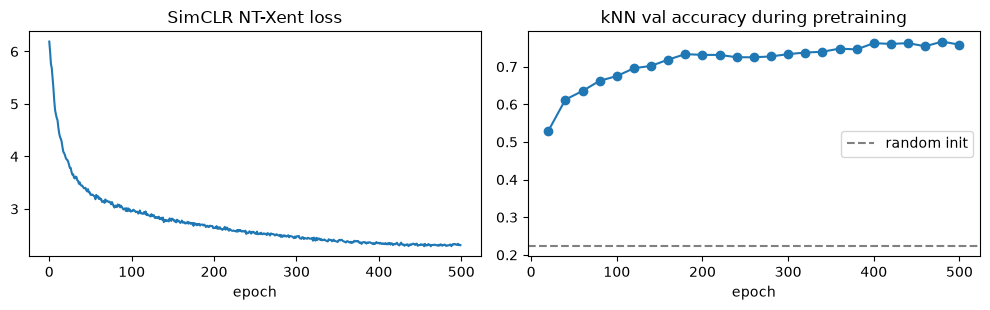

In [13]:
ssl, ssl_log = pretrain_simclr("E2_simclr_pretrain", X_tr, CFG["simclr"])
e2_lin, _ = linear_probe(ssl.backbone); e2_knn = knn_eval(ssl.backbone)
print(f"E2 SimCLR frozen features: linear probe {e2_lin:.3f}, kNN {e2_knn:.3f}")
record("E2a SimCLR + linear probe", e2_lin, "frozen SSL features")

e2ft, e2ft_log = train_classifier("E2_simclr_finetune", X_tr, y_tr, CFG["ft"], init=ssl, lr=1e-3, backbone_lr_mult=0.5)
e2ft_val = acc(predict(e2ft, X_va), y_va)
print(f"E2b SimCLR + fine-tune val {e2ft_val:.3f}")
record("E2b SimCLR + fine-tune", e2ft_val, "SSL init, CE fine-tune", e2ft)

# matched control: same fine-tune recipe (CFG['ft'] epochs) from random init
e2ctl, _ = train_classifier("E2_random_init_ft80", X_tr, y_tr, CFG["ft"], lr=1e-3, backbone_lr_mult=0.5)
e2ctl_val = acc(predict(e2ctl, X_va), y_va)
print(f"E2c control (random init, same fine-tune recipe) val {e2ctl_val:.3f}")
record("E2c random init, same FT recipe", e2ctl_val, "control for E2b", e2ctl)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(ssl_log["loss"]); ax[0].set_title("SimCLR NT-Xent loss"); ax[0].set_xlabel("epoch")
ax[1].plot(ssl_log["knn_epoch"], ssl_log["knn_acc"], "o-"); ax[1].axhline(e0_knn, ls="--", c="gray", label="random init")
ax[1].set_title("kNN val accuracy during pretraining"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

### E3: rotation prediction (simpler pretext task) → fine-tune

In [14]:
rot, rot_log = pretrain_rotation("E3_rotation_pretrain", X_tr, CFG["rot"])
e3_lin, _ = linear_probe(rot.backbone)
print(f"E3 rotation frozen features: linear probe {e3_lin:.3f}, kNN {knn_eval(rot.backbone):.3f}, final rot-acc {rot_log['rot_acc'][-1]:.3f}")
record("E3a Rotation + linear probe", e3_lin, "frozen SSL features")
e3ft, _ = train_classifier("E3_rotation_finetune", X_tr, y_tr, CFG["ft"], init=rot, lr=1e-3, backbone_lr_mult=0.5)
e3ft_val = acc(predict(e3ft, X_va), y_va)
print(f"E3b rotation + fine-tune val {e3ft_val:.3f}")
record("E3b Rotation + fine-tune", e3ft_val, "SSL init, CE fine-tune", e3ft)

[E3_rotation_pretrain] ep  20/200 loss 0.787 rot-acc 0.685 kNN-val 0.406 (40s)


[E3_rotation_pretrain] ep  40/200 loss 0.640 rot-acc 0.744 kNN-val 0.412 (79s)


[E3_rotation_pretrain] ep  60/200 loss 0.550 rot-acc 0.787 kNN-val 0.406 (119s)


[E3_rotation_pretrain] ep  80/200 loss 0.511 rot-acc 0.809 kNN-val 0.438 (159s)


[E3_rotation_pretrain] ep 100/200 loss 0.418 rot-acc 0.847 kNN-val 0.450 (198s)


[E3_rotation_pretrain] ep 120/200 loss 0.371 rot-acc 0.862 kNN-val 0.458 (238s)


... (9 outputs left out)

[E3_rotation_finetune] ep  65/100 loss 0.788 train 0.949 val 0.792 (54s)


[E3_rotation_finetune] ep  81/100 loss 0.747 train 0.960 val 0.794 (67s)


[E3_rotation_finetune] ep  97/100 loss 0.743 train 0.961 val 0.794 (80s)


[E3_rotation_finetune] ep 100/100 loss 0.739 train 0.962 val 0.796 (83s)
E3b rotation + fine-tune val 0.796


### E4: joint supervised + SimCLR training from scratch (with λ = 0 control)

In [15]:
e4, e4_log = train_classifier("E4_joint_lam0.5", X_tr, y_tr, CFG["joint"], aug="simclr", two_view=True, lam=0.5)
e4_val = acc(predict(e4, X_va), y_va)
record("E4a Joint CE + SimCLR (λ=0.5)", e4_val, "from scratch", e4)
e4c, e4c_log = train_classifier("E4_joint_lam0", X_tr, y_tr, CFG["joint"], aug="simclr", two_view=True, lam=0.0)
e4c_val = acc(predict(e4c, X_va), y_va)
record("E4b Two-view CE only (λ=0)", e4c_val, "control for E4a", e4c)
print(f"E4 joint λ=0.5 val {e4_val:.3f} | λ=0 control val {e4c_val:.3f}")

[E4_joint_lam0.5] ep   1/200 loss 5.490 train 0.070 val 0.060 (2s)


[E4_joint_lam0.5] ep  34/200 loss 2.572 train 0.704 val 0.712 (55s)


[E4_joint_lam0.5] ep  67/200 loss 2.145 train 0.867 val 0.773 (109s)


[E4_joint_lam0.5] ep 100/200 loss 1.932 train 0.916 val 0.769 (163s)


[E4_joint_lam0.5] ep 133/200 loss 1.781 train 0.945 val 0.794 (217s)


[E4_joint_lam0.5] ep 166/200 loss 1.697 train 0.958 val 0.821 (271s)


... (6 outputs left out)

[E4_joint_lam0] ep 133/200 loss 0.765 train 0.949 val 0.804 (209s)


[E4_joint_lam0] ep 166/200 loss 0.726 train 0.962 val 0.825 (260s)


[E4_joint_lam0] ep 199/200 loss 0.715 train 0.969 val 0.819 (311s)


[E4_joint_lam0] ep 200/200 loss 0.722 train 0.961 val 0.821 (312s)
E4 joint λ=0.5 val 0.815 | λ=0 control val 0.821


### E5: which augmentations matter for SimCLR here?
Short schedule (100 epochs; 50 with `BUDGET=reduced`) for all four variants, evaluated by linear probe. The "full" variant is retrained
at the same short budget so that all four are comparable.

In [16]:
abl = {}
for a in ["simclr", "no_crop", "no_photo", "no_blur"]:
    m, _ = pretrain_simclr(f"E5_abl_{a}", X_tr, CFG["abl"], aug=a, knn_every=10**9)
    abl[a] = {"linear_probe": linear_probe(m.backbone)[0], "knn": knn_eval(m.backbone)}
abl_df = pd.DataFrame(abl).T.rename(index={"simclr": "full (crop+flip+jitter+blur+solar)"})
display(abl_df.style.format("{:.3f}"))

[E5_abl_simclr] ep 100/100 loss 2.988 kNN-val 0.654 (137s)


[E5_abl_no_crop] ep 100/100 loss 2.038 kNN-val 0.581 (139s)


[E5_abl_no_photo] ep 100/100 loss 2.328 kNN-val 0.508 (138s)


[E5_abl_no_blur] ep 100/100 loss 2.721 kNN-val 0.633 (142s)


,linear_probe,knn
full (crop+flip+jitter+blur+solar),0.727,0.654
no_crop,0.623,0.581
no_photo,0.604,0.508
no_blur,0.694,0.633


### E6: label efficiency
Same train split, but only a stratified fraction of the labels is used. The SimCLR backbone (pretrained on all
1,920 images without labels) is compared with supervised training from scratch on the labelled subset only.

In [17]:
def label_subset(frac, seed=SEED):
    g_ = torch.Generator().manual_seed(seed); keep = []
    for c in range(K):
        idx = torch.nonzero(y_tr == c).flatten(); idx = idx[torch.randperm(len(idx), generator=g_)]
        keep += idx[:max(1, round(frac * len(idx)))].tolist()
    return torch.tensor(sorted(keep))

lab_rows = []
for frac in [0.1, 0.25, 0.5, 1.0]:
    sub = label_subset(frac); Xs, ys = X_tr[sub], y_tr[sub]
    if frac == 1.0:
        sup_val, ft_val = e1_val, e2ft_val
    else:
        m_sup, _ = train_classifier(f"E6_sup_frac{frac}", Xs, ys, CFG["sup"], bs=min(128, len(sub)), verbose=False)
        m_ft, _ = train_classifier(f"E6_simclr_ft_frac{frac}", Xs, ys, CFG["ft"], init=ssl, lr=1e-3,
                                   backbone_lr_mult=0.5, bs=min(128, len(sub)), verbose=False)
        sup_val, ft_val = acc(predict(m_sup, X_va), y_va), acc(predict(m_ft, X_va), y_va)
    lin_val = linear_probe(ssl.backbone, Xs, ys)[0]
    lab_rows.append({"label fraction": frac, "labelled imgs": len(sub), "supervised scratch": sup_val,
                     "SimCLR linear probe": lin_val, "SimCLR fine-tune": ft_val})
    print(lab_rows[-1])
lab_df = pd.DataFrame(lab_rows).set_index("label fraction"); display(lab_df.style.format("{:.3f}", subset=lab_df.columns[1:]))

{'label fraction': 0.1, 'labelled imgs': 192, 'supervised scratch': 0.5333333611488342, 'SimCLR linear probe': 0.6916666666666667, 'SimCLR fine-tune': 0.675000011920929}


{'label fraction': 0.25, 'labelled imgs': 480, 'supervised scratch': 0.668749988079071, 'SimCLR linear probe': 0.7416666666666667, 'SimCLR fine-tune': 0.75}


{'label fraction': 0.5, 'labelled imgs': 960, 'supervised scratch': 0.7437499761581421, 'SimCLR linear probe': 0.7458333333333333, 'SimCLR fine-tune': 0.7749999761581421}


{'label fraction': 1.0, 'labelled imgs': 1920, 'supervised scratch': 0.793749988079071, 'SimCLR linear probe': 0.7645833333333333, 'SimCLR fine-tune': 0.8229166865348816}


,labelled imgs,supervised scratch,SimCLR linear probe,SimCLR fine-tune
label fraction,,,,
0.100000,192,0.533,0.692,0.675
0.250000,480,0.669,0.742,0.750
0.500000,960,0.744,0.746,0.775
1.000000,1920,0.794,0.765,0.823


### E7: best recipe
Built from the findings above (see the discussion at the end). It combines SimCLR initialisation with
fine-tuning under the joint objective, so the contrastive term keeps acting as a regulariser while the
classifier is learned. It uses a longer schedule and flip test-time augmentation (TTA).

In [18]:
e7, e7_log = train_classifier("E7_best_simclr_init_joint", X_tr, y_tr, CFG["best"], init=ssl, aug="simclr",
                              two_view=True, lam=0.5, lr=1e-3, backbone_lr_mult=0.5)
e7_val = acc(predict(e7, X_va), y_va); e7_val_tta = acc(predict(e7, X_va, tta=True), y_va)
print(f"E7 val {e7_val:.3f} | with flip-TTA {e7_val_tta:.3f}")
record("E7 Best: SimCLR init + joint FT", e7_val, "SSL pretrain, then CE+NT-Xent fine-tune", e7)

[E7_best_simclr_init_joint] ep   1/200 loss 3.648 train 0.070 val 0.108 (2s)


[E7_best_simclr_init_joint] ep  34/200 loss 1.898 train 0.858 val 0.800 (57s)


[E7_best_simclr_init_joint] ep  67/200 loss 1.725 train 0.940 val 0.802 (112s)


[E7_best_simclr_init_joint] ep 100/200 loss 1.651 train 0.953 val 0.802 (168s)


[E7_best_simclr_init_joint] ep 133/200 loss 1.590 train 0.966 val 0.815 (224s)


[E7_best_simclr_init_joint] ep 166/200 loss 1.560 train 0.968 val 0.812 (279s)


[E7_best_simclr_init_joint] ep 199/200 loss 1.553 train 0.969 val 0.817 (335s)


[E7_best_simclr_init_joint] ep 200/200 loss 1.563 train 0.971 val 0.815 (337s)


E7 val 0.815 | with flip-TTA 0.823


## 6. Overfitting: train vs. validation curves

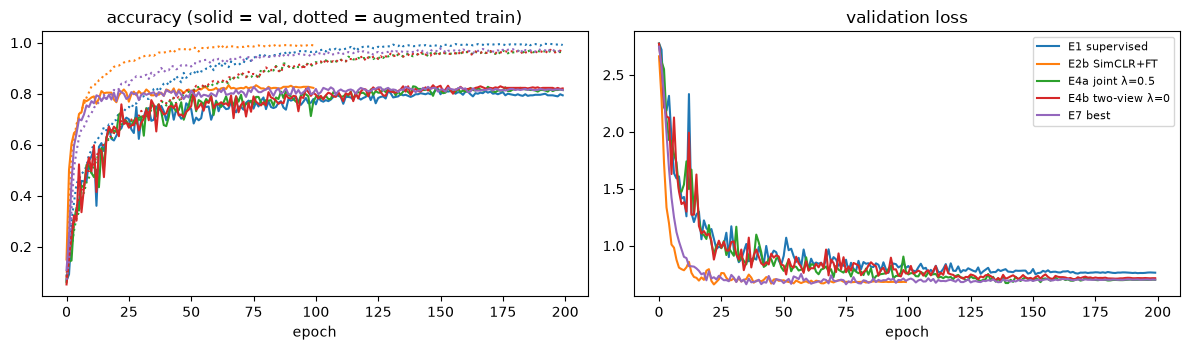

,clean train acc,val acc,gap
model,,,
E1 supervised,1.000,0.794,0.206
E2b SimCLR+FT,1.000,0.823,0.177
E4a joint λ=0.5,1.000,0.815,0.185
E4b two-view λ=0,1.000,0.821,0.179
E7 best,1.000,0.815,0.185


In [19]:
curves = {"E1 supervised": e1_log, "E2b SimCLR+FT": e2ft_log, "E4a joint λ=0.5": e4_log,
          "E4b two-view λ=0": e4c_log, "E7 best": e7_log}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for k_, lg in curves.items():
    l, = ax[0].plot(lg["val_acc"], label=k_); ax[0].plot(lg["train_acc"], ls=":", c=l.get_color())
    ax[1].plot(lg["val_loss"], label=k_, c=l.get_color())
ax[0].set_title("accuracy (solid = val, dotted = augmented train)"); ax[0].set_xlabel("epoch")
ax[1].set_title("validation loss"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

gap_rows = []
for k_, m in [("E1 supervised", e1), ("E2b SimCLR+FT", e2ft), ("E4a joint λ=0.5", e4), ("E4b two-view λ=0", e4c), ("E7 best", e7)]:
    tr_a = acc(predict(m, X_tr), y_tr); va_a = acc(predict(m, X_va), y_va)
    gap_rows.append({"model": k_, "clean train acc": tr_a, "val acc": va_a, "gap": tr_a - va_a})
display(pd.DataFrame(gap_rows).set_index("model").style.format("{:.3f}"))

## 7. Test-set evaluation (run once, after all choices were made on validation)

In [20]:
rows = []
probe_backbones = {"E0 random-init + linear probe": rand_net.backbone, "E2a SimCLR + linear probe": ssl.backbone,
                   "E3a Rotation + linear probe": rot.backbone}
for name, r in RESULTS.items():
    if "model" in r:
        tta = name.startswith("E7")
        te = acc(predict(r["model"], X_test, tta=tta), y_test)
    else:
        bb = probe_backbones[name]; _, (sc, clf) = linear_probe(bb)
        te = clf.score(sc.transform(features(bb, X_test).numpy()), y_test.numpy())
    rows.append({"method": name, "val acc": r["val"], "test acc": te, "note": r["note"]})
res_df = pd.DataFrame(rows).set_index("method")
res_df.to_csv(RUN_DIR / "experiment_summary.csv")
display(res_df.style.format("{:.3f}", subset=["val acc", "test acc"]))

,val acc,test acc,note
method,,,
E0 random-init + linear probe,0.340,0.285,frozen random features
E1 supervised baseline,0.794,0.740,CE only
E2a SimCLR + linear probe,0.765,0.743,frozen SSL features
E2b SimCLR + fine-tune,0.823,0.783,"SSL init, CE fine-tune"
"E2c random init, same FT recipe",0.783,0.750,control for E2b
E3a Rotation + linear probe,0.613,0.623,frozen SSL features
E3b Rotation + fine-tune,0.796,0.760,"SSL init, CE fine-tune"
E4a Joint CE + SimCLR (λ=0.5),0.815,0.770,from scratch
E4b Two-view CE only (λ=0),0.821,0.752,control for E4a


Best model (E7) test accuracy: 79.8% (319/400)


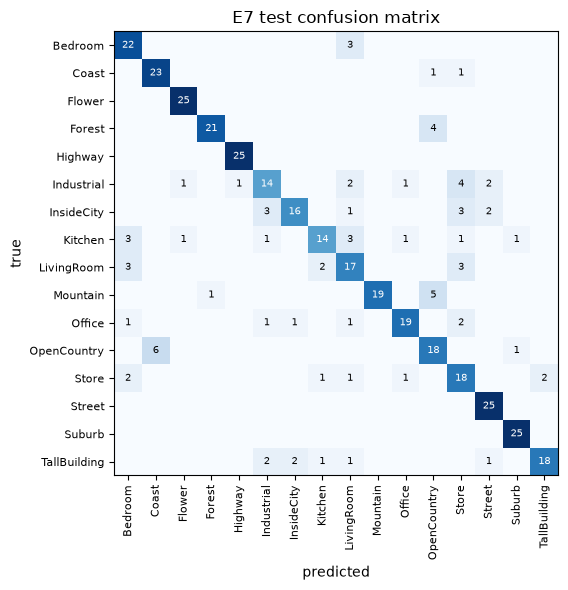

largest confusions (true -> predicted, count): [('OpenCountry', 'Coast', 6), ('Mountain', 'OpenCountry', 5), ('Forest', 'OpenCountry', 4), ('Industrial', 'Store', 4), ('Bedroom', 'LivingRoom', 3), ('InsideCity', 'Industrial', 3), ('InsideCity', 'Store', 3), ('Kitchen', 'Bedroom', 3), ('Kitchen', 'LivingRoom', 3), ('LivingRoom', 'Bedroom', 3), ('LivingRoom', 'Store', 3)]


In [21]:
best_logits = predict(e7, X_test, tta=True); best_test = acc(best_logits, y_test)
print(f"Best model (E7) test accuracy: {best_test*100:.1f}% ({int(round(best_test*len(y_test)))}/{len(y_test)})")
cm = confusion_matrix(y_test.numpy(), best_logits.argmax(1).numpy())
fig, ax = plt.subplots(figsize=(7, 6)); im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(K)); ax.set_yticks(range(K)); ax.set_xticklabels(CLASSES, rotation=90, fontsize=8); ax.set_yticklabels(CLASSES, fontsize=8)
for i in range(K):
    for j in range(K):
        if cm[i, j]: ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > 12 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("E7 test confusion matrix"); plt.tight_layout(); plt.show()
off = [(CLASSES[i], CLASSES[j], int(cm[i, j])) for i in range(K) for j in range(K) if i != j and cm[i, j] >= 3]
print("largest confusions (true -> predicted, count):", sorted(off, key=lambda t: -t[2]))

In [22]:
# save best checkpoint, config and test2 predictions
torch.save({"state_dict": e7.state_dict(), "classes": CLASSES, "mean": MEAN, "std": STD, "img": IMG, "store": STORE},
           RUN_DIR / "best_model.pt")
(RUN_DIR / "config.json").write_text(json.dumps({"seed": SEED, "epochs": CFG, "aug": AUG, "img": IMG, "store": STORE,
                                                  "device": DEVICE, "epoch_scale": EPOCH_SCALE}, indent=1))
if X_test2 is not None:
    p2 = predict(e7, X_test2, tta=True).argmax(1)
    pd.DataFrame({"file": [f.name for f in test2_files], "pred": [CLASSES[i] for i in p2]}).to_csv(RUN_DIR / "test2_predictions.csv", index=False)
    print("wrote", RUN_DIR / "test2_predictions.csv")

wrote runs/test2_predictions.csv


## 8. Discussion
The numbers this cell prints come from the runs above. The written interpretation is in the report.

In [23]:
print(res_df[["val acc", "test acc"]].map(lambda v: f"{v*100:.1f}%").to_string())
print("\nAugmentation ablation (linear probe, short SimCLR schedule):\n", abl_df.map(lambda v: f"{v*100:.1f}%").to_string())
print("\nLabel efficiency (val):\n", lab_df.to_string())

# save every number the report needs in one file
summary = {"device": DEVICE, "epochs": CFG, "n_train_split": len(tr_idx), "n_val": len(va_idx), "n_test": len(y_test),
           "results": res_df.reset_index().to_dict(orient="records"),
           "ablation": abl_df.reset_index().rename(columns={"index": "variant"}).to_dict(orient="records"),
           "label_efficiency": lab_df.reset_index().to_dict(orient="records"),
           "overfitting": gap_rows, "e1_probe": {"linear": e1_lin}, "e0": {"knn": e0_knn, "linear": e0_lin},
           "e2": {"linear": e2_lin, "knn": e2_knn, "knn_curve": [ssl_log["knn_epoch"], ssl_log["knn_acc"]]},
           "e3_final_rot_acc": rot_log["rot_acc"][-1], "e7": {"val": e7_val, "val_tta": e7_val_tta, "test_tta": best_test},
           "test_confusions": off, "train_time_s": {k_: json.loads(log_path(k_).read_text()).get("time_s")
                                                     for k_ in [p.stem for p in RUN_DIR.glob("*.json") if p.stem.startswith("E")]}}
(RUN_DIR / "results_summary.json").write_text(json.dumps(summary, indent=1, default=float))
print("wrote", RUN_DIR / "results_summary.json")

                                val acc test acc
method                                          
E0 random-init + linear probe     34.0%    28.5%
E1 supervised baseline            79.4%    74.0%
E2a SimCLR + linear probe         76.5%    74.2%
E2b SimCLR + fine-tune            82.3%    78.3%
E2c random init, same FT recipe   78.3%    75.0%
E3a Rotation + linear probe       61.3%    62.3%
E3b Rotation + fine-tune          79.6%    76.0%
E4a Joint CE + SimCLR (λ=0.5)     81.5%    77.0%
E4b Two-view CE only (λ=0)        82.1%    75.2%
E7 Best: SimCLR init + joint FT   81.5%    79.8%

Augmentation ablation (linear probe, short SimCLR schedule):
                                    linear_probe    knn
full (crop+flip+jitter+blur+solar)        72.7%  65.4%
no_crop                                   62.3%  58.1%
no_photo                                  60.4%  50.8%
no_blur                                   69.4%  63.3%

Label efficiency (val):
                 labelled imgs  supervised scratc